# Tracking efficiency by charge and detector half — tiered definitions

This notebook follows up `Tracking_Efficiency_SVT_Hits.ipynb` and the review in `Review.md`. It tightens the
efficiency definition and splits every result into **e⁺ / e⁻** and **top / bottom** half of the SVT.

**What changed with respect to the first notebook**

- **Efficiency is reported in cumulative tiers** instead of a single "found" flag:

  | tier | a truth particle passes it if … |
  |---|---|
  | found | a track has this particle on ≥ 50 % of its hits (and on more hits than any other particle) |
  | clean | … and that track has at most 1 hit from another particle |
  | good p | … and the track momentum is within 15 % of the true momentum |
  | in time | … and the track time is within ±6 ns of the signal time of the sample |
  | ECal match | … and the reconstructed particle built from the track has the ECal cluster made by this same particle |

- **The denominator is explicit.** Two acceptances are used:
  - *ECal acceptance*: the particle's own shower deposits more than 100 MeV in the ECal (independent of the SVT).
    Particles in the beam gap between the top and bottom SVT halves, |tan λ| < 0.015, are reported separately.
  - *SVT acceptance*: the particle has a reconstructed hit in at least 8 SVT layers. This uses reconstructed hits, so
    it is not independent of the detector, but it does not depend on reaching the ECal.
- **Categories:** charge from the true PDG code; half from the sign of the true tan λ (truth particles) or of the
  reconstructed tan λ (tracks). The recoil electron and the pair electron of a trident cannot be told apart and are
  both counted as e⁻.

**Main finding added after review (§4a):** the worse momentum resolution of bottom-half electrons is a real
detector feature, not an analysis artefact. The whole L9 bottom electron-side *stereo* sensor is dead in the 2021
conditions (and has no hits in data), so most bottom electrons have no stereo (bend-plane) measurement beyond L8.

Colour encodes the charge (red e⁺, blue e⁻). Filled circles are the top half, open squares the bottom half.
Samples (pure MC and MC with pulser-data overlay) are always in separate panels.

**Input provenance** (from the `metadata_json` object in each MiniDST; detector from `dumpevent` on the first and last recon file)

| Sample | MiniDST made from (SLCIO) | Files | hps-java detector |
|---|---|---|---|
| pure | `/net/data/endeavour2/HPS/physrun2021/home_made_mc/tritrig_pure_run14272/recon/tritrig_3pt74_recon_*.slcio` | 474 | `HPS_Run2021Pass1_v9_14272` |
| overlay | `/net/data/endeavour2/HPS/physrun2021/home_made_mc/tritrig_pulser_beamspot_run14272/recon/tritrig_pulser_3pt74_recon_*.slcio` | 601 | `HPS_Run2021Pass1_v9_14272` |

MiniDSTs written by LcioReader / MiniDST 1.6.0.

In [1]:
import sys, time
sys.path.insert(0, "..")                 # make the Analysis package importable
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from Analysis import svt_tracking as st

st.setup(n_threads=32)
st.mpl_style()
CATS = st.CATEGORIES
LABEL = {k: s.label for k, s in st.SAMPLES.items()}

N_FILES = None                          # None = all files
ECAL = "tp_acc && !tp_gap"               # ECal acceptance, outside the beam gap
GAP  = "tp_acc && tp_gap"                # ECal acceptance, inside the beam gap |tan(lambda)| < 0.015
SVT  = "tp_n_layers >= 8"                # SVT acceptance: reconstructed hits in >= 8 layers

## Book all histograms

All quantities are booked for both samples and the four categories, then filled in one event loop per sample.

In [2]:
TB = st.int_bins(0, len(st.TIERS))   # tp_tier = number of tiers passed (0 ... 5)
LB = st.layer_bins()
PB = (14, 0.2, 3.0)                  # true momentum bins [GeV]

def book(df):
    h = {"n_events": st.book_hist(df, "1", (1, 0, 2)),
         "bkg_top": st.book_hist(df, "hit_layer", LB, where="hit_is_mc == 0 && hit_top"),
         "bkg_bot": st.book_hist(df, "hit_layer", LB, where="hit_is_mc == 0 && !hit_top"),
         "mc_top":  st.book_hist(df, "hit_layer", LB, where="hit_is_mc == 1 && hit_top"),
         "mc_bot":  st.book_hist(df, "hit_layer", LB, where="hit_is_mc == 1 && !hit_top")}
    for c, sel in CATS.items():
        tp = sel["tp"]
        h[c] = dict(
            tiers_ecal = st.book_hist(df, "tp_tier", TB, where=f"{tp} && {ECAL}"),
            tiers_gap  = st.book_hist(df, "tp_tier", TB, where=f"{tp} && {GAP}"),
            tiers_svt  = st.book_hist(df, "tp_tier", TB, where=f"{tp} && {SVT}"),
            found_p    = st.book_ratio(df, "tp_p", "tp_found", PB, where=f"{tp} && {ECAL}"),
            chain_p    = st.book_ratio(df, "tp_p", "tp_ecal_match", PB, where=f"{tp} && {ECAL}"),
            found_p_svt= st.book_ratio(df, "tp_p", "tp_found", PB, where=f"{tp} && {SVT}"),
            dup        = st.book_ratio(df, "tp_p", "tp_n_tracks > 1", (1, 0, 10), where=f"{tp} && tp_found && {ECAL}"),
            has_clus   = st.book_ratio(df, "tp_p", "svt::take_or(trk_cluster, tp_track, -1) >= 0", (1, 0, 10),
                                       where=f"{tp} && tp_in_time && {ECAL}"),
            dp         = st.book_hist2d(df, "tp_p", "tp_trk_dp_rel", PB, (800, -1, 1), where=f"{tp} && tp_found && {SVT}"),
            missing    = st.book_ratio_of(df, f"svt::mask_to_layers(tp_missing[tp_found && {tp}])",
                                              f"svt::mask_to_layers(tp_layers[tp_found && {tp}])", LB),
            wrong      = st.book_ratio_of(df, f"svt::mask_to_layers(trk_wrong[trk_matched && {sel['trk']}])",
                                              f"svt::mask_to_layers(trk_layers[trk_matched && {sel['trk']}])", LB),
            # layers with a truth hit, for particles in the SVT acceptance (divide by the number of particles)
            cover      = st.book_hist(df, f"svt::mask_to_layers(tp_layers[{tp} && {SVT}])", LB),
            # resolution vs. number of stereo hits in L9-L14 on the matched track
            dp_st_back = st.book_hist2d(df, "svt::popcount(tp_trk_stereo & svt::kBackLayers)", "tp_trk_dp_rel",
                                        st.int_bins(0, 3), (800, -1, 1), where=f"{tp} && tp_found && {SVT}"),
            wrong_l9   = st.book_ratio(df, "trk_p", "(trk_wrong & 256) != 0", (1, 0, 100),
                                       where=f"trk_matched && {sel['trk']}"),
        )
    for q, sel in {"e+": "tp_pos", "e-": "!tp_pos"}.items():
        h[q] = dict(
            acc_p    = st.book_ratio(df, "tp_p", "tp_acc", PB, where=f"{sel} && {SVT}"),
            n_tp     = st.book_hist(df, "tp_p", (1, 0, 100), where=sel),
            found_tl = st.book_ratio(df, "tp_tanl", "tp_found", (40, -0.08, 0.08), where=f"{sel} && tp_acc"),
            chain_tl = st.book_ratio(df, "tp_tanl", "tp_ecal_match", (40, -0.08, 0.08), where=f"{sel} && tp_acc"),
        )
    # L9 hits per event by module (0/2 top, 1/3 bottom; 0/1 electron side, 2/3 positron side)
    h["mod9"] = st.book_hist(df, "svt_hit_module[hit_sel]", st.int_bins(0, 3), where="hit_layer == 9")
    return h

def book_data(df):
    """Truth-free cross-check on real data: L9 hits per event by module."""
    return {"n_events": st.book_hist(df, "1", (1, 0, 2)),
            "mod9": st.book_hist(df, "hit_module", st.int_bins(0, 3), where="hit_layer == 9")}

H = {key: book(st.load(key, n_files=N_FILES)) for key in st.SAMPLES}
D = book_data(st.load_hits("run14229", n_files=3))      # 3 files of run 14229 (~0.4 M events) are plenty
t0 = time.time()
st.run(H, D)
print(f"Event loop: {time.time() - t0:.0f} s for " +
      ", ".join(f"{H[k]['n_events'].counts[0]:,.0f} {k}" for k in H) + " events")

Event loop: 10 s for 1,009,136 pure, 993,781 overlay events


## 1. Who is in the denominator?

Before comparing efficiencies, it matters which particles enter them. The plot shows, for particles that cross at
least 8 SVT layers, the fraction that also deposits > 100 MeV in the ECal.


- **Positrons above 0.6 GeV almost always reach the ECal.** That is expected: they bend towards the side the ECal
  covers, and every event was triggered by an ECal cluster. Below 0.6 GeV the two samples differ (0.98 in pure,
  0.19 in overlay at 0.5 GeV). This is probably a trigger difference: the pure sample uses the singles2+3 trigger,
  the overlay uses the singles trigger with pulser merging.
- **Electrons reach the ECal only in a window of about 0.8–1.8 GeV.** Softer electrons bend out of the calorimeter.
  Harder ones, mostly recoil electrons, go into the ECal beam hole.
- **Consequence:** the ECal-based denominator has only 0.15 electrons per event, against 0.39 in the SVT acceptance.
  ECal-based electron efficiencies therefore describe a narrow momentum range. The SVT acceptance is the better
  denominator for electrons.

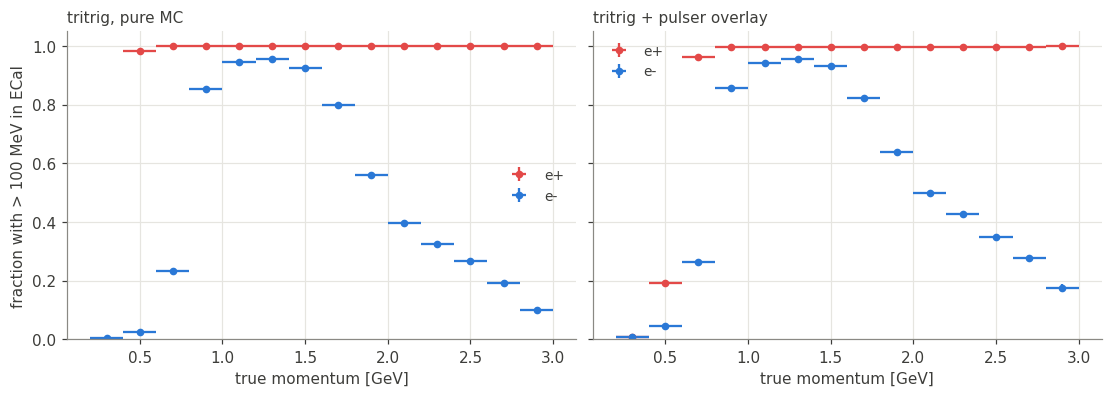

Particles per event in each denominator


ECal acc. (no gap)  ECal acc. (gap)  SVT acc. (>= 8 layers)
sample  category                                                              
pure    e+ top                  0.418            0.072                   0.481
        e+ bottom               0.416            0.093                   0.497
        e- top                  0.074            0.012                   0.202
        e- bottom               0.073            0.014                   0.194
overlay e+ top                  0.406            0.070                   0.469
        e+ bottom               0.401            0.089                   0.482
        e- top                  0.075            0.024                   0.195
        e- bottom               0.075            0.025                   0.188

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, k in zip(axes, H):
    for q in ("e+", "e-"):
        st.plot_ratio(ax, H[k][q]["acc_p"], label=q, color=st.CHARGE_COLORS[q], min_total=20)
    st.style(ax, "true momentum [GeV]", "fraction with > 100 MeV in ECal" if ax is axes[0] else None, LABEL[k])
    ax.set_ylim(0, 1.05)
plt.show()

rows = []
for k in H:
    n_ev = H[k]["n_events"].counts[0]
    for c in CATS:
        n = [H[k][c][t].counts.sum() for t in ("tiers_ecal", "tiers_gap", "tiers_svt")]
        rows.append(dict(sample=k, category=c, **{"ECal acc. (no gap)": n[0] / n_ev, "ECal acc. (gap)": n[1] / n_ev,
                                                   "SVT acc. (>= 8 layers)": n[2] / n_ev}))
print("Particles per event in each denominator")
pd.DataFrame(rows).set_index(["sample", "category"]).round(3)

## 2. Tiered efficiency

Each curve starts at the fraction of particles with a matched track ("found") and drops as stricter requirements are
added. The lower panels use the SVT acceptance, which keeps the many electrons that never reach the ECal; the
"ECal match" tier is not shown there because it needs an ECal shower.


- **Positrons in pure MC:** nearly all are found (0.999). Each further tier costs 1–2 %, ending at 0.95 (top) and
  0.93 (bottom) for the full chain.
- **Background hurts mostly at the "clean" tier.** Positrons are still found at 0.99, but only 0.84 (top) and 0.91
  (bottom) of the found tracks have at most one wrong hit. The full chain drops to 0.78 (top) and 0.83 (bottom).
- **The top half is clearly worse with background.** It has 37 % more background hits than the bottom (§5).
- **Electrons are worse at every tier, even without background:**
  - found: 0.94–0.95 instead of 0.999;
  - good p: a large drop, worst for the bottom half (0.95 → 0.81 in pure MC);
  - ECal match: a further 6–9 % lost.
  - The momentum resolution in §4 explains the "good p" drop; for the bottom half it is caused by a dead
    L9 stereo sensor (§4a).
- **Beam gap:** positrons in the gap are found at 0.83, but only about 0.40 pass the full chain with background.
  Gap electrons are essentially never found (≈ 0.1).

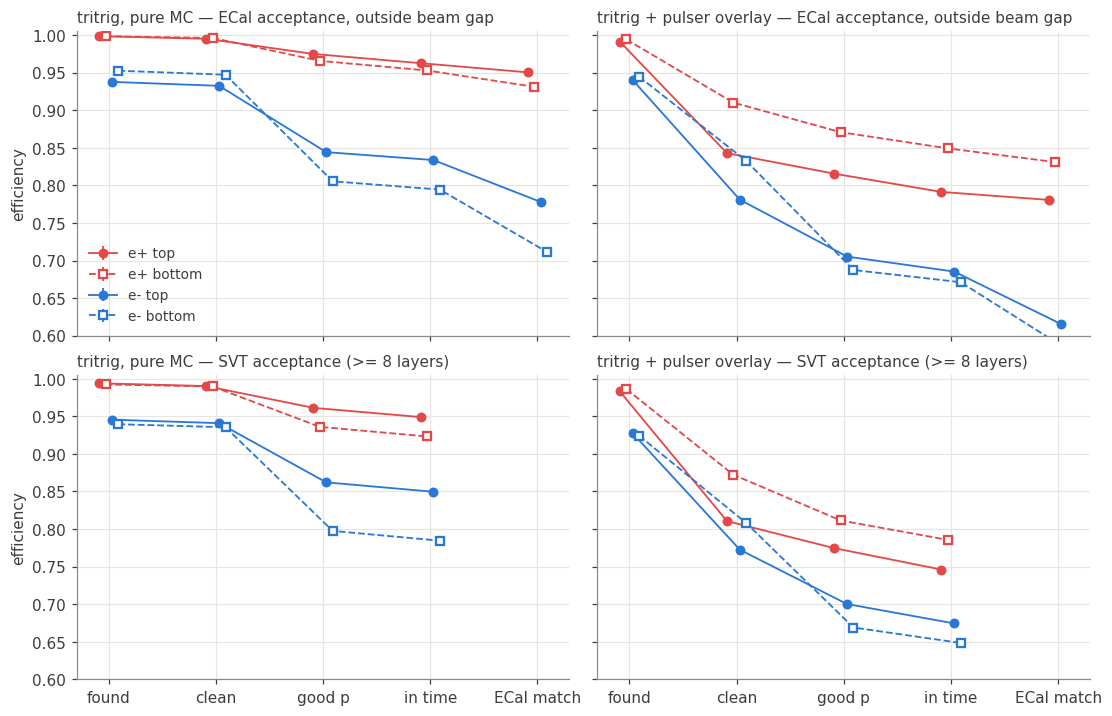

ECal acceptance, outside the beam gap


N  found  clean  good p  in time  ECal match
sample  category                                                    
pure    e+ top     421996  0.999  0.995   0.975    0.963       0.950
        e+ bottom  420113  0.999  0.996   0.966    0.953       0.931
        e- top      74751  0.938  0.932   0.844    0.834       0.778
        e- bottom   73920  0.953  0.947   0.805    0.794       0.711
overlay e+ top     403165  0.991  0.843   0.816    0.791       0.781
        e+ bottom  398370  0.994  0.910   0.871    0.849       0.831
        e- top      74918  0.940  0.781   0.705    0.685       0.615
        e- bottom   74522  0.945  0.833   0.687    0.671       0.581

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.4), sharex=True, sharey="row")
x = np.arange(len(st.TIERS))
for col, k in enumerate(H):
    for row, (den, ntier) in enumerate((("tiers_ecal", 5), ("tiers_svt", 4))):
        ax = axes[row, col]
        for i, c in enumerate(CATS):
            eff, err, n = st.tier_efficiency(H[k][c][den])
            ax.errorbar(x[:ntier] + 0.06 * (i - 1.5), eff[:ntier], yerr=err[:, :ntier], lw=1.2, ms=5, capsize=0,
                        label=c, **st.cat_style(c, line=True))
        acc = "ECal acceptance, outside beam gap" if den == "tiers_ecal" else "SVT acceptance (>= 8 layers)"
        st.style(ax, None, "efficiency" if col == 0 else None, f"{LABEL[k]} — {acc}", legend=(row == 0 and col == 0))
        ax.set_xticks(x, st.TIERS)
axes[0, 0].set_ylim(0.6, 1.005); axes[1, 0].set_ylim(0.6, 1.005)
plt.show()

def tier_table(den, ntier=5):
    rows = []
    for k in H:
        for c in CATS:
            eff, err, n = st.tier_efficiency(H[k][c][den])
            rows.append(dict(sample=k, category=c, N=int(n), **dict(zip(st.TIERS[:ntier], eff[:ntier]))))
    return pd.DataFrame(rows).set_index(["sample", "category"]).round(3)

print("ECal acceptance, outside the beam gap")
tier_table("tiers_ecal")

In [5]:
print("ECal acceptance, inside the beam gap |tan(lambda)| < 0.015")
display(tier_table("tiers_gap"))
print("SVT acceptance (>= 8 layers with a reconstructed hit)")
display(tier_table("tiers_svt", 4))

ECal acceptance, inside the beam gap |tan(lambda)| < 0.015


N  found  clean  good p  in time  ECal match
sample  category                                                   
pure    e+ top     72622  0.836  0.831   0.755    0.744       0.714
        e+ bottom  94344  0.829  0.824   0.674    0.663       0.594
        e- top     12423  0.102  0.100   0.045    0.045       0.035
        e- bottom  14232  0.097  0.095   0.048    0.047       0.035
overlay e+ top     69115  0.830  0.520   0.437    0.415       0.400
        e+ bottom  88520  0.852  0.596   0.442    0.422       0.383
        e- top     24205  0.087  0.030   0.010    0.010       0.007
        e- bottom  25111  0.098  0.044   0.017    0.016       0.011

SVT acceptance (>= 8 layers with a reconstructed hit)


N  found  clean  good p  in time
sample  category                                        
pure    e+ top     484992  0.994  0.990   0.961    0.949
        e+ bottom  501394  0.992  0.990   0.936    0.923
        e- top     203864  0.946  0.941   0.862    0.850
        e- bottom  195663  0.939  0.935   0.797    0.785
overlay e+ top     466483  0.983  0.811   0.775    0.746
        e+ bottom  478637  0.986  0.872   0.811    0.786
        e- top     193984  0.927  0.772   0.700    0.674
        e- bottom  186512  0.924  0.808   0.669    0.648

### Where the last two tiers lose particles

For particles that pass the "in time" tier but fail "ECal match", the table separates tracks that are not linked to
any ECal cluster from tracks linked to a cluster made by a different particle. Duplicates are found particles with
more than one matched track.


- **"Wrong cluster" is negligible.** When a track is linked to a cluster, the cluster almost always belongs to the
  same particle.
- **"No cluster" is the loss.** For positrons it is 1–2 % (more in the bottom half). For electrons it is 6–9 %, again
  worse in the bottom half.
- **Duplicates** (two tracks for one particle) are 0.1 % in pure MC and 1–2.4 % with background. The top half has
  more.

In [6]:
rows = []
for k in H:
    for c in CATS:
        eff, err, n = st.tier_efficiency(H[k][c]["tiers_ecal"])
        in_time, matched = eff[3], eff[4]
        no_clus = in_time * (1 - H[k][c]["has_clus"].eff[0])
        rows.append({"sample": k, "category": c, "in time": in_time, "no cluster": no_clus,
                     "wrong cluster": max(in_time - matched - no_clus, 0.0), "ECal match": matched,
                     "duplicates (of found)": H[k][c]["dup"].eff[0]})
pd.DataFrame(rows).set_index(["sample", "category"]).round(3)

in time  no cluster  wrong cluster  ECal match  \
sample  category                                                    
pure    e+ top       0.963       0.012            0.0       0.950   
        e+ bottom    0.953       0.022            0.0       0.931   
        e- top       0.834       0.056            0.0       0.778   
        e- bottom    0.794       0.083            0.0       0.711   
overlay e+ top       0.791       0.011            0.0       0.781   
        e+ bottom    0.849       0.018            0.0       0.831   
        e- top       0.685       0.070            0.0       0.615   
        e- bottom    0.671       0.089            0.0       0.581   

                   duplicates (of found)  
sample  category                          
pure    e+ top                     0.001  
        e+ bottom                  0.001  
        e- top                     0.001  
        e- bottom                  0.000  
overlay e+ top                     0.024  
        e+ bottom                  0.019  
        e- top                     0.023  
        e- bottom                  0.009

## 3. Efficiency versus momentum and tan λ

Upper row: "found" efficiency; lower row: the full chain up to "ECal match", both for particles in the ECal
acceptance outside the beam gap. Bins with fewer than 50 particles are not shown.


- **Positron "found" efficiency is flat at ≈ 1.** The full chain is flat at 0.93–0.95 in pure MC, and at 0.75–0.80
  (top) and 0.83–0.86 (bottom) with background, so the top–bottom gap is present at all momenta.
- **Electron "found" efficiency is 0.94–0.97 at all momenta**, i.e. about 3–5 % below positrons, with or without
  background.
- **The electron full chain peaks at 0.8–0.85 near 1–1.5 GeV in pure MC.** It falls at lower momentum, where the
  track reaches the edge of the ECal.

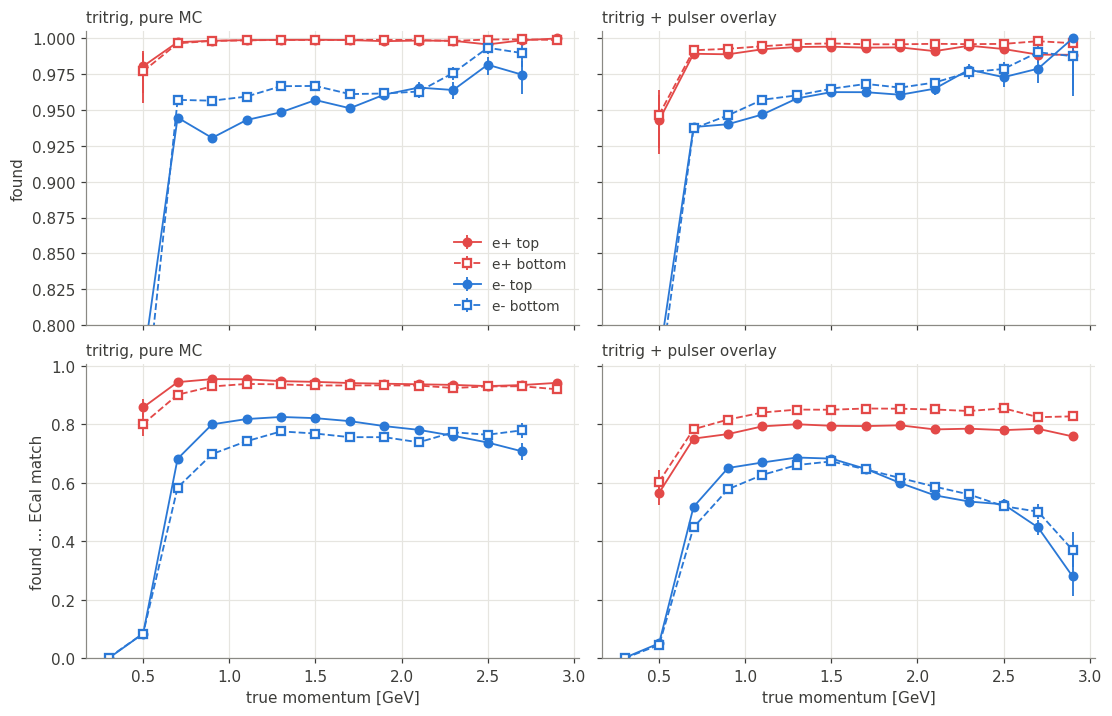

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.4), sharex=True, sharey="row")
for col, k in enumerate(H):
    for row, name in enumerate(("found_p", "chain_p")):
        ax = axes[row, col]
        for c in CATS:
            r = H[k][c][name]
            ok = r.total >= 50
            ax.errorbar(r.centers[ok], r.eff[ok], yerr=r.err[:, ok], lw=1.2, ms=5, capsize=0, label=c,
                        **st.cat_style(c, line=True))
        st.style(ax, "true momentum [GeV]" if row else None,
                 ("found" if row == 0 else "found ... ECal match") if col == 0 else None,
                 LABEL[k], legend=(row == 0 and col == 0))
axes[0, 0].set_ylim(0.8, 1.005); axes[1, 0].set_ylim(0.0, 1.005)
plt.show()

The tan λ view uses all particles in the ECal acceptance, including the beam gap (shaded). Top is tan λ > 0.


- **Positrons:** "found" is close to 1 everywhere outside the gap, and the full chain is flat.
- **Electrons:** the full chain depends strongly on |tan λ|. It drops near the gap and at large |tan λ| (the edges of
  the ECal), while "found" stays high. So for electrons the ECal match, not the tracking, sets the shape.
- **Bottom positrons near the gap** (−0.03 < tan λ < −0.015) pass the full chain less often than top positrons at the
  same |tan λ|.

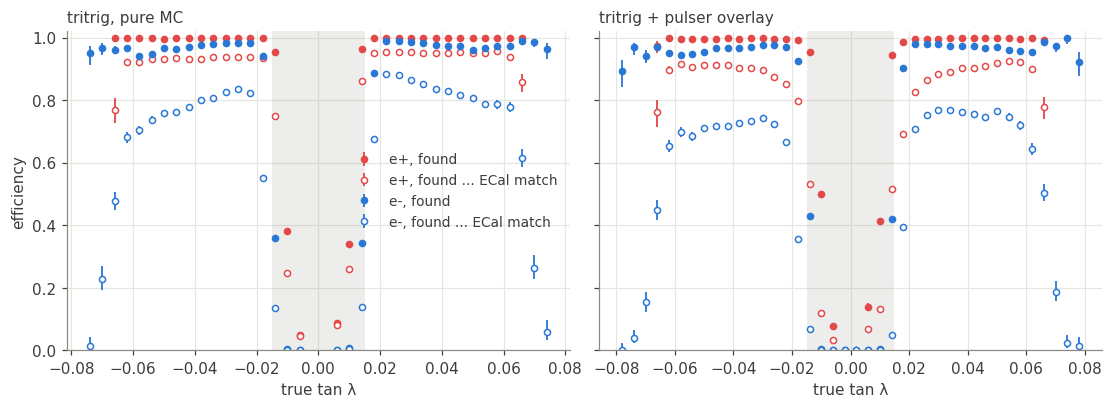

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, k in zip(axes, H):
    ax.axvspan(-0.015, 0.015, color=st.COLORS["muted"], alpha=0.15, lw=0)
    for q in ("e+", "e-"):
        for name, mfc, lab in (("found_tl", None, "found"), ("chain_tl", "white", "found ... ECal match")):
            r = H[k][q][name]
            ok = r.total >= 50
            ax.errorbar(r.centers[ok], r.eff[ok], yerr=r.err[:, ok], fmt="o", ms=4, lw=1.2, capsize=0,
                        color=st.CHARGE_COLORS[q], mfc=mfc or st.CHARGE_COLORS[q], label=f"{q}, {lab}")
    st.style(ax, "true tan λ", "efficiency" if ax is axes[0] else None, LABEL[k], legend=(ax is axes[0]))
    ax.set_ylim(0, 1.02)
plt.show()

## 4. Momentum resolution

Half-width of the central 68 % of (p_reco − p_true)/p_true for found particles in the SVT acceptance. The 15 %
"good p" cut of the tiers is several times this width except at the lowest momenta.


- **Pure MC resolution:**

  | category | σ(Δp/p) |
  |---|---|
  | e⁺ top | ≈ 3 % |
  | e⁺ bottom | ≈ 3.5 % |
  | e⁻ top | ≈ 4 % |
  | e⁻ bottom | 6–9 % |

- **The bottom electrons are a clear outlier**, at all momenta and in both samples. §4a shows why: a dead L9
  stereo sensor. The resolution of all electrons also grows above 1.5 GeV: these are mostly recoil electrons close
  to the beam, which leave the back layers through the gap between the hole and slot sensors and so have fewer
  hits in L9–L14.
- **The median shows a −0.5 to −1 % bias for all categories** (energy loss). With background, the electron bias
  grows to −2 to −4 % at high momentum.
- **The top–bottom difference is real, not an analysis artefact.** At the same hit pattern, top and bottom
  tracks have the same resolution (§4a).

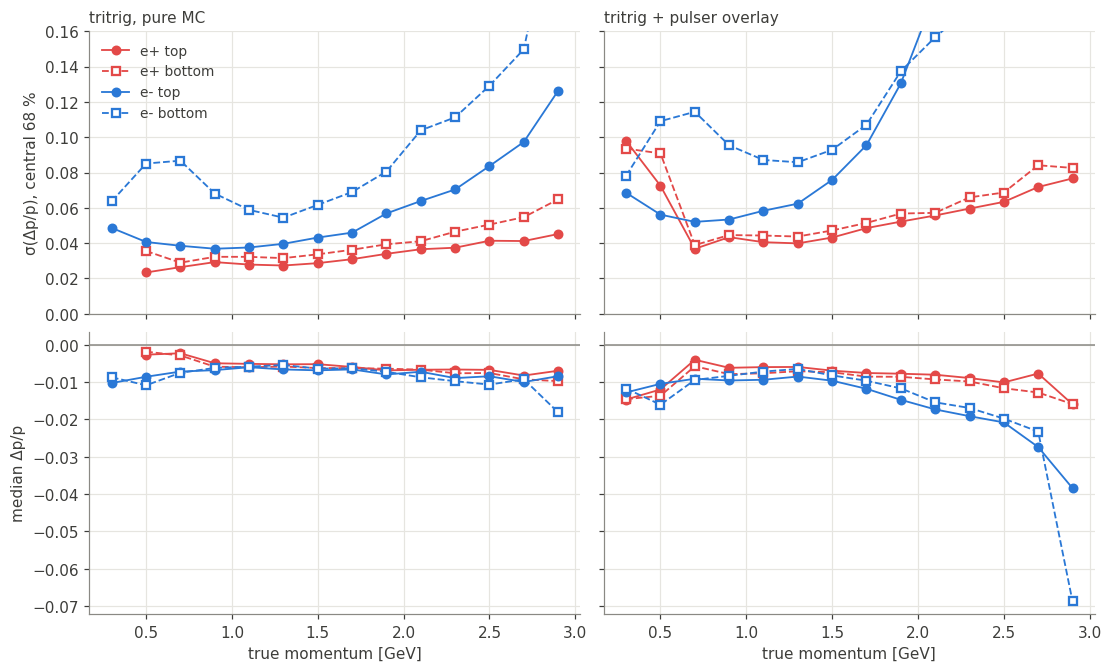

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.0), sharex=True, sharey="row")
for col, k in enumerate(H):
    for c in CATS:
        med, width = st.central_width(H[k][c]["dp"], min_entries=100)
        centers = 0.5 * (H[k][c]["dp"].xedges[1:] + H[k][c]["dp"].xedges[:-1])
        axes[0, col].plot(centers, width, ms=5, lw=1.2, label=c, **st.cat_style(c, line=True))
        axes[1, col].plot(centers, med, ms=5, lw=1.2, label=c, **st.cat_style(c, line=True))
    st.style(axes[0, col], None, "σ(Δp/p), central 68 %" if col == 0 else None, LABEL[k], legend=(col == 0))
    st.style(axes[1, col], "true momentum [GeV]", "median Δp/p" if col == 0 else None, None, legend=False)
    axes[1, col].axhline(0, color=st.COLORS["muted"], lw=1)
axes[0, 0].set_ylim(0, 0.16)
plt.show()

### 4a. Why bottom electrons are worse: a dead L9 stereo sensor

**How HPS measures momentum.** The field is vertical, so tracks bend in the horizontal plane. The axial strips
measure *y* (the non-bend coordinate, which drives the vertex resolution). Only the stereo strips, tilted by
100 mrad (L1–L4) or 50 mrad (L5–L14), measure the bend. Sensor orientation is mirrored between the halves: in the
**top** half the **even** layers are stereo, in the **bottom** half the **odd** layers are stereo
(`svt_daq_map` in the conditions DB, and the layer map in `KalmanParams.java`).

**What is dead.** The 2021 bad-channel list (`svt_bad_channels`, "Dead Channels for 2021 Run", runs 14000–15000)
used for this MC marks these sensors:

In [10]:
pd.Series(st.DEAD_SENSORS, name="dead channels").to_frame()

,dead channels
"L9 bottom, electron side, stereo (svt_hit_module 1)","640 / 640 strips: whole sensor, also no hits i..."
"L13 top, electron side, axial",128 / 640 strips (one APV25)
"L14 top, positron side, stereo",54 / 640 strips


Layers 9–14 have two sensors per half: one on the electron side (`svt_hit_module` 0 top, 1 bottom) and one on the
positron side (2 top, 3 bottom). The figure shows (a) which layers the particles actually leave a hit in, and (b)
L9 hits per event by module in the two MC samples and in **real data** (run 14229, 3 files).

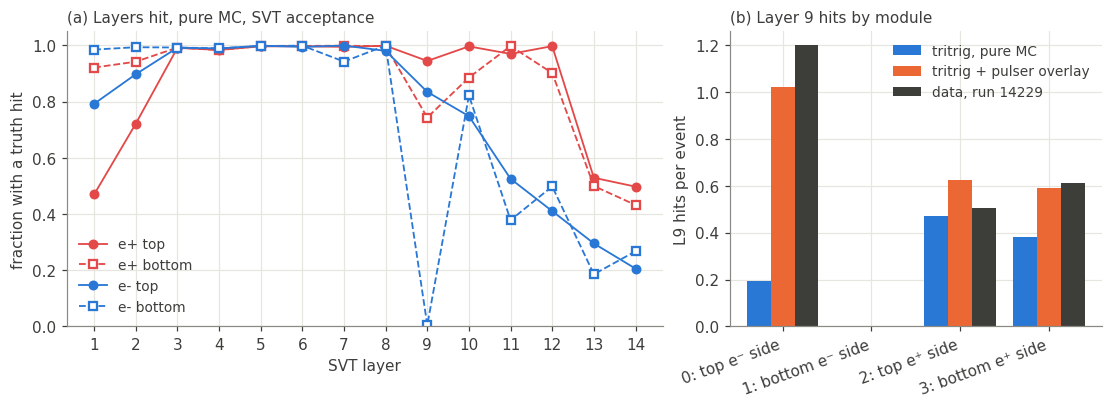

In [11]:
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw=dict(width_ratios=[1.6, 1]))
for c in CATS:
    n = H["pure"][c]["tiers_svt"].counts.sum()
    a.plot(st.LAYERS, H["pure"][c]["cover"].counts / n, ms=5, lw=1.2, label=c, **st.cat_style(c, line=True))
a.set_xticks(st.LAYERS); a.set_ylim(0, 1.05)
st.style(a, "SVT layer", "fraction with a truth hit", "(a) Layers hit, pure MC, SVT acceptance")

mods = ["0: top e⁻ side", "1: bottom e⁻ side", "2: top e⁺ side", "3: bottom e⁺ side"]
src = [(LABEL["pure"], H["pure"], st.COLORS["pure"]), (LABEL["overlay"], H["overlay"], st.COLORS["overlay"]),
       ("data, run 14229", D, st.COLORS["ink"])]
x = np.arange(4)
for i, (lab, h, col) in enumerate(src):
    b.bar(x + 0.27 * (i - 1), h["mod9"].counts / h["n_events"].counts[0], width=0.27, color=col, label=lab)
b.set_xticks(x, mods, rotation=20, ha="right")
st.style(b, None, "L9 hits per event", "(b) Layer 9 hits by module")
plt.show()

- **L9 bottom, electron side has no hits at all**, in MC and in data. Only 0.5 % of bottom electrons have an L9
  hit (from the positron-side sensor), against 85 % of top electrons. Bottom positrons that cross the electron-side
  sensor lose it too (75 % have an L9 hit, against 95 % for top positrons).
- **This removes a stereo measurement from the bottom half only.** In the bottom, L9 is a stereo layer; in the top
  it is axial. The next bottom stereo layers, L11 and L13, are reached by only 40 % and 20 % of bottom electrons. So
  for most bottom electrons the last bend-plane measurement is L7 (z ≈ 300 mm) instead of L9–L13 (z ≈ 500–900 mm).
- **L1 and L2 top also start further from the beam than L1 and L2 bottom.** Top particles need |tan λ| ≳ 0.02 for
  an L1 hit, bottom particles only ≳ 0.012. That is why only 47 % of top positrons (which cluster near the gap) have
  an L1 hit. The same asymmetry is in data: on run-14229 tracks with ≥ 10 hits, p > 0.8 GeV and in time, 60 % (top)
  and 85 % (bottom) have an L1 hit. This costs mainly vertex resolution, not momentum resolution, because L1 top is
  axial.
- The MC reproduces the data on both points, so the MC resolution difference is what the data should show too.

**Test of the explanation.** If the dead sensor is the cause, top and bottom tracks with the same number of stereo
hits in the back layers must have the same resolution:

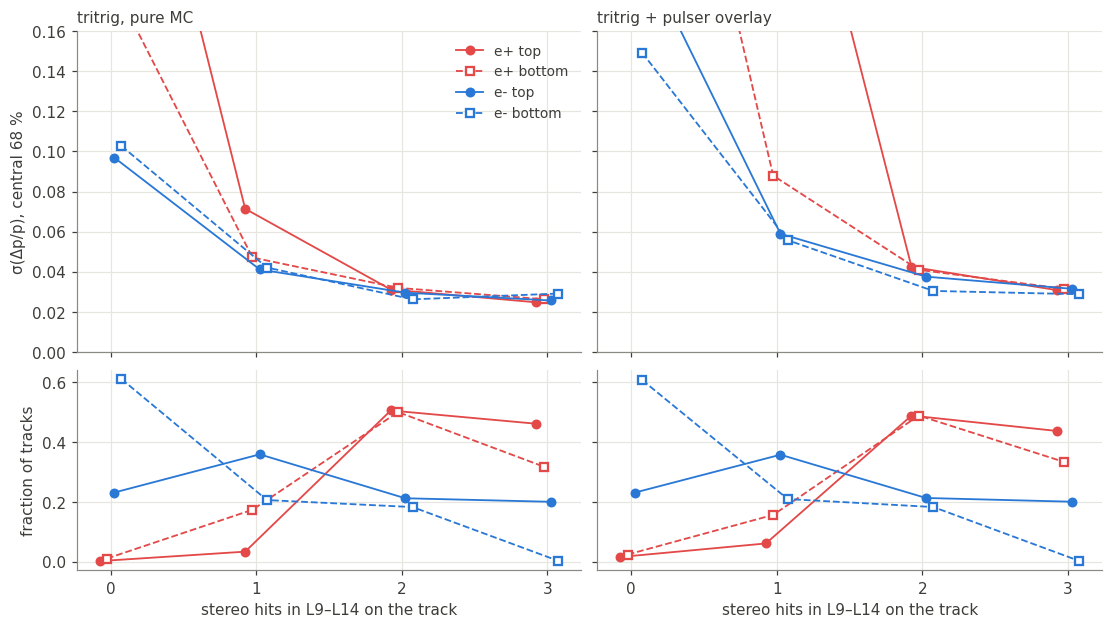

σ, 0 stereo  σ, 1 stereo  σ, 2 stereo  σ, 3 stereo  \
sample  category                                                        
pure    e+ top           0.362        0.071        0.031        0.025   
        e+ bottom        0.190        0.047        0.032        0.026   
        e- top           0.097        0.041        0.030        0.026   
        e- bottom        0.103        0.042        0.026        0.029   
overlay e+ top           0.345        0.326        0.042        0.031   
        e+ bottom        0.399        0.088        0.041        0.031   
        e- top           0.207        0.059        0.038        0.031   
        e- bottom        0.149        0.056        0.030        0.029   

                   frac, 0 stereo  frac, 1 stereo  frac, 2 stereo  \
sample  category                                                    
pure    e+ top              0.002           0.033           0.505   
        e+ bottom           0.010           0.173           0.499   
        e- top              0.231           0.358           0.212   
        e- bottom           0.610           0.205           0.182   
overlay e+ top              0.015           0.061           0.488   
        e+ bottom           0.024           0.156           0.488   
        e- top              0.231           0.357           0.212   
        e- bottom           0.606           0.209           0.182   

                   frac, 3 stereo  
sample  category                   
pure    e+ top              0.460  
        e+ bottom           0.317  
        e- top              0.200  
        e- bottom           0.003  
overlay e+ top              0.436  
        e+ bottom           0.333  
        e- top              0.200  
        e- bottom           0.003

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(10, 5.6), sharex=True, sharey="row",
                         gridspec_kw=dict(height_ratios=[1.6, 1]))
nb_ = np.arange(4)
rows = []
for col, k in enumerate(H):
    for i, c in enumerate(CATS):
        h2 = H[k][c]["dp_st_back"]
        _, width = st.central_width(h2, min_entries=100)
        frac = h2.counts.sum(axis=1) / h2.counts.sum()
        axes[0, col].plot(nb_ + 0.05 * (i - 1.5), width, ms=5, lw=1.2, label=c, **st.cat_style(c, line=True))
        axes[1, col].plot(nb_ + 0.05 * (i - 1.5), frac, ms=5, lw=1.2, label=c, **st.cat_style(c, line=True))
        rows.append(dict(sample=k, category=c, **{f"σ, {n} stereo": w for n, w in zip(nb_, width)},
                         **{f"frac, {n} stereo": f for n, f in zip(nb_, frac)}))
    st.style(axes[0, col], None, "σ(Δp/p), central 68 %" if col == 0 else None, LABEL[k], legend=(col == 0))
    st.style(axes[1, col], "stereo hits in L9–L14 on the track", "fraction of tracks" if col == 0 else None,
             None, legend=False)
    axes[1, col].set_xticks(nb_)
axes[0, 0].set_ylim(0, 0.16)
plt.show()
pd.DataFrame(rows).set_index(["sample", "category"]).round(3)

- **At equal stereo count, top and bottom agree.** For electrons the top and bottom curves coincide: in pure MC
  σ(Δp/p) is about 10 % with no back-layer stereo hit, 4 % with one, and 2.5–3 % with two or three. Positrons agree
  too where they live (2–3 stereo hits, > 80 % of positron tracks). The few positron tracks with 0–1 back-layer
  stereo hits (< 6 % in the top) are a small, different population and are worse. The overlay adds wrong hits, so
  its values are higher, but the top–bottom agreement is the same.
- **Only the population differs.** 61 % of bottom electrons have no stereo hit in L9–L14 (top: 23 %), and almost none
  have three. For positrons the bottom half has 17 % with a single back-layer stereo hit (top: 3 %).
- **So the explanation is complete.** The worse bottom-electron resolution, the larger "good p" loss of bottom
  electrons in §2 and the smaller bottom-positron loss all follow from the dead L9 bottom stereo sensor. It is the
  same in data and is not a reconstruction or analysis bug.
- **Consequences.**
  - Analyses of 2021 data should expect worse momentum (and invariant-mass) resolution for bottom-half electrons,
    and should check that the MC hit-killing and dead-channel list keep matching the data.
  - For the hit-filtering study: a hit filter must not remove the few remaining back-layer stereo hits of bottom
    electrons. Report filter performance per half and per category.

## 5. Missing and wrong hits per layer

First the background itself: overlaid-data hits per event in each layer, for the top and bottom halves, next to the
hits from the trident event.


- **The top half carries more background:** 67.6 against 49.4 hits per event. Most of the difference is in L1–L4
  (L1: 22 against 14 hits per event).
- **The trident hits are the same in both halves** (about 0.6–0.8 per layer and event).
- This asymmetry explains why top tracks pick up more wrong hits and pass the "clean" tier less often.

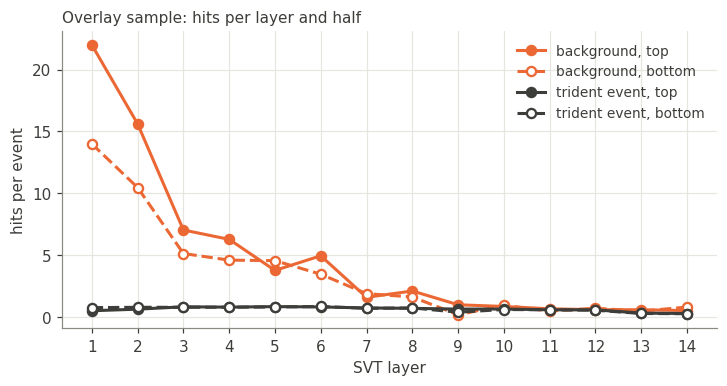

background hits per event, top / bottom: 67.6 / 49.4


In [13]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
n_ev = H["overlay"]["n_events"].counts[0]
for name, lab, mfc in (("bkg_top", "background, top", None), ("bkg_bot", "background, bottom", "white")):
    ax.plot(st.LAYERS, H["overlay"][name].counts / n_ev, "o", color=st.COLORS["overlay"], mfc=mfc or st.COLORS["overlay"],
            mew=1.5, ls="-" if mfc is None else "--", label=lab)
for name, lab, mfc in (("mc_top", "trident event, top", None), ("mc_bot", "trident event, bottom", "white")):
    ax.plot(st.LAYERS, H["overlay"][name].counts / n_ev, "o", color=st.COLORS["ink"], mfc=mfc or st.COLORS["ink"],
            mew=1.5, ls="-" if mfc is None else "--", label=lab)
ax.set_xticks(st.LAYERS)
st.style(ax, "SVT layer", "hits per event", "Overlay sample: hits per layer and half")
plt.show()
print("background hits per event, top / bottom:",
      f"{H['overlay']['bkg_top'].counts.sum() / n_ev:.1f} / {H['overlay']['bkg_bot'].counts.sum() / n_ev:.1f}")

Missing and wrong hits per layer:

*Missing*: the particle has a reconstructed hit in the layer, but its matched track does not use it.
*Wrong*: a hit on a matched track that belongs to a different particle (or to the overlaid background).


- **Wrong hits follow the background.** Top positrons pick up a wrong hit in L1 on 34 % of matched tracks; bottom
  positrons on 19 %. Top tracks also have more wrong hits in L2–L4.
- **Missing hits in L1–L2** (≈ 20 %) are similar for all categories. In L3–L4, top positrons lose more (15 % against
  8 %).
- **L11–L14 lose 5–13 % of hits even without background**, for all categories.
- **The L9 spike for bottom electrons is a normalisation effect of the dead sensor (§4a).** Their own L9 sensor is
  dead, so almost none of their tracks has an L9 hit, and the few that do often picked it up from another particle.
  The fraction is large (13 % pure, 35 % overlay) but the denominator is tiny; per track, the rate is below 0.1 %
  (table below the figure). The large error bars in L9 show this.

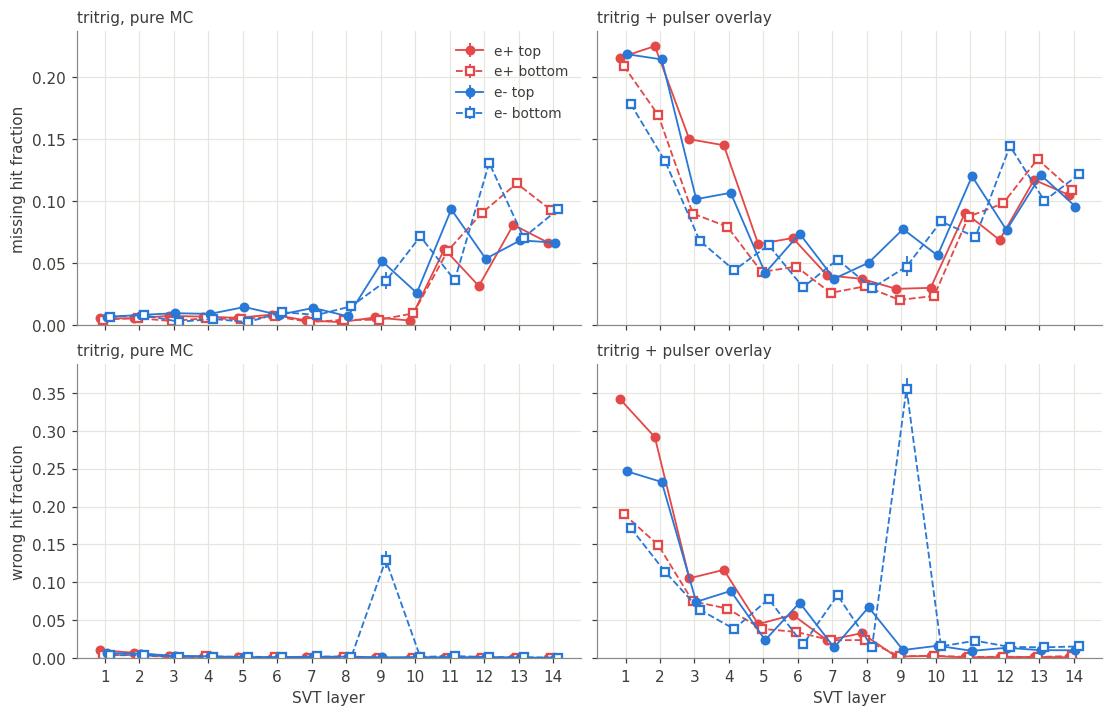

Matched tracks with a wrong hit in L9, per track:


,e+ top,e+ bottom,e- top,e- bottom
pure,0.0001,0.0001,0.0009,0.0007
overlay,0.0019,0.0020,0.0085,0.0027


In [14]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.4), sharex=True, sharey="row")
for col, k in enumerate(H):
    for row, name in enumerate(("missing", "wrong")):
        ax = axes[row, col]
        for i, c in enumerate(CATS):
            r = H[k][c][name]
            ax.errorbar(r.centers + 0.1 * (i - 1.5), r.eff, yerr=r.err, lw=1.2, ms=5, capsize=0, label=c,
                        **st.cat_style(c, line=True))
        st.style(ax, "SVT layer" if row else None, f"{name} hit fraction" if col == 0 else None, LABEL[k],
                 legend=(row == 0 and col == 0))
        ax.set_xticks(st.LAYERS)
axes[0, 0].set_ylim(0, None); axes[1, 0].set_ylim(0, None)
plt.show()

print("Matched tracks with a wrong hit in L9, per track:")
pd.DataFrame({k: {c: H[k][c]["wrong_l9"].integral()[0] for c in CATS} for k in H}).T.round(4)

## Summary


| | e⁺ top | e⁺ bottom | e⁻ top | e⁻ bottom |
|---|---|---|---|---|
| found, pure / overlay | 0.999 / 0.991 | 0.999 / 0.994 | 0.938 / 0.940 | 0.953 / 0.945 |
| full chain (to ECal match), pure / overlay | 0.950 / 0.781 | 0.931 / 0.831 | 0.778 / 0.615 | 0.711 / 0.581 |
| L1 wrong-hit fraction, overlay | 0.34 | 0.19 | 0.25 | 0.17 |

*ECal acceptance, outside the beam gap; full samples.*

1. **Track finding is not the problem for positrons.** With background they are still found 99 % of the time, but
   about 15 % (top) and 9 % (bottom) of those tracks carry wrong hits, which degrades momentum and timing. Hit
   filtering should target exactly this.
2. **Top and bottom differ for two reasons.**
   - *Background:* the top half has 37 % more background hits, mostly in L1–L4, and correspondingly more wrong hits
     and duplicates. Any hit filter should be tuned per half and per layer.
   - *Detector:* the L9 bottom electron-side stereo sensor is dead, and L1–L2 top start further from the beam than
     L1–L2 bottom. Both are in the conditions/geometry and in data (§4a).
3. **Electrons are worse even without background:**
   - found efficiency about 5 % lower;
   - worse momentum resolution. In the bottom half this is explained (§4a): the L9 bottom electron-side stereo
     sensor is dead in the 2021 detector (conditions DB and data), so 61 % of bottom electrons have no stereo hit
     in L9–L14. At equal stereo-hit count top and bottom resolutions agree;
   - 6–9 % lost because the track is not linked to an ECal cluster.
4. **The ECal acceptance is a poor denominator for electrons.** It covers only 0.8–1.8 GeV. Use the SVT acceptance,
   or true sensor crossings, which need the simulated tracker hits.

**Next steps suggested by these results**
- ~~Investigate the bottom-electron problem~~: done in §4a (dead L9 bottom electron-side stereo sensor).
- Find why about 5 % of electrons are not found in pure MC: no track at all, or a track with purity below 0.5.
- Make the hit-filter study per half and per layer, starting with L1–L4 top, using the raw-hit samples
  (`minidst_plus`).